# 07 · Marketing: channel response curves & budget optimizer

**Business problem.** ~EGP 220M was spent across six channels. Which channels are efficient *at the margin*, where do returns diminish,
and how should a fixed budget be re-split?

**Method (a lightweight cousin of Marketing-Mix Modelling):** per channel, regress `log(attributed orders)` on `log(spend)` with controls
(campaign duration, year, target audience). The coefficient on `log(spend)` is the **elasticity β**: β = 0.6 means doubling spend yields only ~52% more orders.
A constrained optimizer (SciPy SLSQP) then re-allocates the same total budget; a **bootstrap** tells us how confident we can be that the new split really is better.

**Important data caveat (found in notebook 00):** campaign-reported "attributed orders" are many times larger than the whole sales ledger.
They are platform claims, not incremental sales. Therefore we trust **relative** efficiency between channels and the *shape* of the curves, **not absolute order counts**.
We also did not build a full Bayesian MMM (PyMC): with ~2,200 campaigns and no weekly sales-by-channel series, adstock/saturation parameters would not be identifiable.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                       # lets the notebook import the `cottonil` package
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cottonil import config as cfg
from cottonil.data_io import load_table, load_sales_lines, load_product_master, week_start, quick_profile
from cottonil.plotting import setup, NAVY, TEAL, ORANGE, RED, PALETTE
setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

DATA_DIR = cfg.find_data_dir()
SOURCE = cfg.data_source(DATA_DIR)
print(f"Data folder : {DATA_DIR}")
print(f"Data source : {SOURCE.upper()}" + ("   <-- synthetic test data; retrain on real data before trusting any number" if SOURCE == "synthetic" else ""))

Data folder : D:\HVIA Internship\task 2\cottonil-ai\COTTONIL_Data
Data source : REAL


In [2]:
from cottonil import marketing as MK
mk = load_table("marketing_campaigns")
mk["duration"] = (mk.end_date - mk.start_date).dt.days.clip(lower=1)
mk["year"] = mk.start_date.dt.year
mk = mk[(mk.spend_EGP > 0) & (mk.orders_attributed > 0)].copy()
mk["cpo"] = mk.spend_EGP / mk.orders_attributed
print(f"{len(mk):,} campaigns | total spend EGP {mk.spend_EGP.sum() / 1e6:,.1f}M | attributed orders {mk.orders_attributed.sum():,} (vs {len(load_table('sales_orders')):,} real orders in the ledger)")
ch_sum = mk.groupby("channel").agg(campaigns=("campaign_id", "size"), spend_m=("spend_EGP", lambda s: s.sum() / 1e6), orders=("orders_attributed", "sum")).assign(avg_cpo=lambda d: d.spend_m * 1e6 / d.orders).sort_values("avg_cpo")
ch_sum.round(2)

2,200 campaigns | total spend EGP 219.5M | attributed orders 24,106,747 (vs 540,000 real orders in the ledger)


,campaigns,spend_m,orders,avg_cpo
channel,,,,
Meta Ads,387,38.63,4603025,8.39
In-store,363,36.22,4303403,8.42
SMS / CRM,328,33.92,3679103,9.22
Google Ads,382,37.78,4035521,9.36
Influencers,373,35.38,3718093,9.52
Outdoor,367,37.59,3767602,9.98


## 1 · Fit log-log response per channel

In [3]:
def design(df, years, auds):
    cols = [np.log(df.spend_EGP), np.log(df.duration)]
    cols += [(df.year == y).astype(float) for y in years[1:]] + [(df.target_audience == a).astype(float) for a in auds[1:]]
    return np.column_stack([np.ones(len(df))] + cols)

years, auds = sorted(mk.year.unique()), sorted(mk.target_audience.unique())
def fit_channel(df):
    X, y = design(df, years, auds), np.log(df.orders_attributed.values)
    coef, *_ = np.linalg.lstsq(X, y, rcond=None); return coef

# --- honest validation: fit on the earlier 80% of campaigns, test on the latest 20% (by start date) ---
mk = mk.sort_values("start_date"); cut = mk.start_date.quantile(.8)
rows = []
for c, g in mk.groupby("channel"):
    tr, te = g[g.start_date <= cut], g[g.start_date > cut]
    coef = fit_channel(tr); pred = design(te, years, auds) @ coef; yt = np.log(te.orders_attributed.values)
    base = np.log(tr.orders_attributed).mean()
    r2 = 1 - ((yt - pred) ** 2).sum() / ((yt - base) ** 2).sum()
    rows.append({"channel": c, "beta (train)": coef[1], "holdout R2 vs mean": r2, "holdout MAPE": np.mean(np.abs(np.exp(pred) / te.orders_attributed.values - 1))})
val = pd.DataFrame(rows).set_index("channel"); val.round(3)

,beta (train),holdout R2 vs mean,holdout MAPE
channel,,,
Google Ads,0.939,0.318,2.088
In-store,0.915,0.213,0.870
Influencers,0.946,0.412,1.581
Meta Ads,1.124,0.489,2.297
Outdoor,0.822,0.323,2.292
SMS / CRM,1.012,0.345,1.651


In [4]:
# --- bootstrap the full-data fit: elasticity + uncertainty ---
rng = np.random.default_rng(0); B = 300
chs = sorted(mk.channel.unique()); last12 = mk[mk.start_date > mk.start_date.max() - pd.Timedelta(days=365)]
beta_pt, c0_pt, beta_bs, c0_bs = {}, {}, {c: [] for c in chs}, {c: [] for c in chs}
for c in chs:
    g, g12 = mk[mk.channel == c], last12[last12.channel == c]
    coef = fit_channel(g); beta_pt[c] = coef[1]
    c0_pt[c] = float(np.mean(design(g12, years, auds) @ coef - coef[1] * np.log(g12.spend_EGP)))      # intercept incl. controls at recent levels
    for _ in range(B):
        gb = g.sample(len(g), replace=True, random_state=int(rng.integers(1e9))); cb = fit_channel(gb)
        beta_bs[c].append(cb[1]); c0_bs[c].append(float(np.mean(design(g12, years, auds) @ cb - cb[1] * np.log(g12.spend_EGP))))
beta_tab = pd.DataFrame({"beta": beta_pt, "ci_low": {c: np.percentile(beta_bs[c], 2.5) for c in chs}, "ci_high": {c: np.percentile(beta_bs[c], 97.5) for c in chs}})
beta_tab["interpretation"] = np.where(beta_tab.ci_high < 1, "diminishing returns", np.where(beta_tab.ci_low > 1, "increasing returns", "~linear (cannot tell)"))
beta_tab.round(3)

,beta,ci_low,ci_high,interpretation
Google Ads,0.961,0.832,1.092,~linear (cannot tell)
In-store,0.937,0.815,1.071,~linear (cannot tell)
Influencers,0.954,0.849,1.067,~linear (cannot tell)
Meta Ads,1.087,0.989,1.195,~linear (cannot tell)
Outdoor,0.891,0.777,1.008,~linear (cannot tell)
SMS / CRM,0.957,0.824,1.120,~linear (cannot tell)


## 2 · Response curves & marginal cost per order

marginal cost = what the NEXT EGP buys; much higher than average => saturated channel
             annual spend (EGP M)  avg cost/order  marginal cost/order  marginal / average
In-store                     4.21           12.00                12.80                1.07
Meta Ads                     5.64           16.71                15.38                0.92
Google Ads                   4.26           16.39                17.06                1.04
Influencers                  3.84           17.24                18.07                1.05
SMS / CRM                    4.29           18.53                19.36                1.04
Outdoor                      7.07           18.36                20.60                1.12


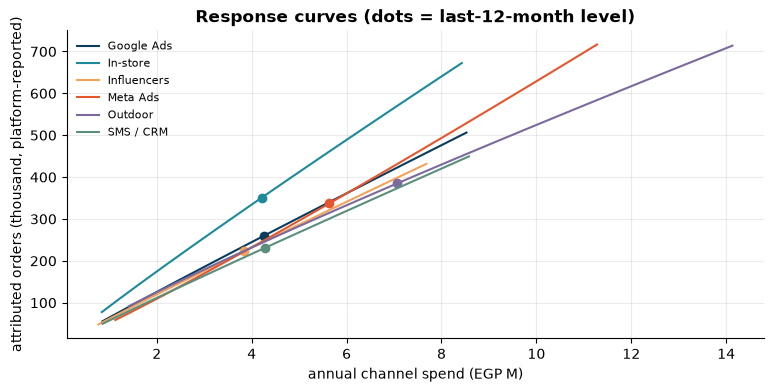

In [5]:
n_c = {c: int((last12.channel == c).sum()) for c in chs}; S_c = {c: float(last12[last12.channel == c].spend_EGP.sum()) for c in chs}
params = {"channels": chs, "beta": beta_pt, "c0": c0_pt, "n": n_c, "spend_current": S_c}
cur_orders = {c: MK.channel_orders(params, c, S_c[c]) for c in chs}
marg = pd.DataFrame({"annual spend (EGP M)": {c: S_c[c] / 1e6 for c in chs}, "avg cost/order": {c: S_c[c] / cur_orders[c] for c in chs},
                     "marginal cost/order": {c: S_c[c] / cur_orders[c] / beta_pt[c] for c in chs}}).round(2)
marg["marginal / average"] = (marg["marginal cost/order"] / marg["avg cost/order"]).round(2)
print("marginal cost = what the NEXT EGP buys; much higher than average => saturated channel")
display(marg.sort_values("marginal cost/order")) if "display" in globals() else print(marg.sort_values("marginal cost/order"))
fig, ax = plt.subplots(figsize=(9, 4))
for c, col in zip(chs, PALETTE):
    s = np.linspace(.2, 2.0, 40) * S_c[c]; ax.plot(s / 1e6, [MK.channel_orders(params, c, x) / 1e3 for x in s], color=col, label=c)
    ax.plot(S_c[c] / 1e6, cur_orders[c] / 1e3, "o", color=col)
ax.set_xlabel("annual channel spend (EGP M)"); ax.set_ylabel("attributed orders (thousand, platform-reported)"); ax.set_title("Response curves (dots = last-12-month level)"); ax.legend(fontsize=8); plt.show()

## 3 · Optimise the same total budget
Each channel may move between 50% and 150% of today's level (a realistic guard-rail – we do not extrapolate far outside observed spend).

In [6]:
opt = MK.optimize(params, lo=.5, hi=1.5)
mix = pd.DataFrame({"current EGP M": {c: S_c[c] / 1e6 for c in chs}, "optimised EGP M": {c: opt["alloc"][c] / 1e6 for c in chs}})
mix["change %"] = (mix["optimised EGP M"] / mix["current EGP M"] - 1) * 100
print(f"success: {opt['success']} | attributed orders: {opt['orders_current'] / 1e3:,.0f}k -> {opt['orders'] / 1e3:,.0f}k  ({opt['orders'] / opt['orders_current'] - 1:+.1%}) at the SAME total budget")
mix.round(1)

success: True | attributed orders: 1,788k -> 1,894k  (+5.9%) at the SAME total budget

,current EGP M,optimised EGP M,change %
Google Ads,4.3,6.4,50.0
In-store,4.2,6.3,50.0
Influencers,3.8,2.5,-36.0
Meta Ads,5.6,8.5,50.0
Outdoor,7.1,3.5,-50.0
SMS / CRM,4.3,2.1,-50.0


lift of recommended split across 300 bootstrap fits: median +6.6%, 90% interval [+0.2%, +11.8%], P(lift > 0) = 96%  [covers sampling noise only - NOT attribution bias or extrapolation to the 50%/150% bounds]


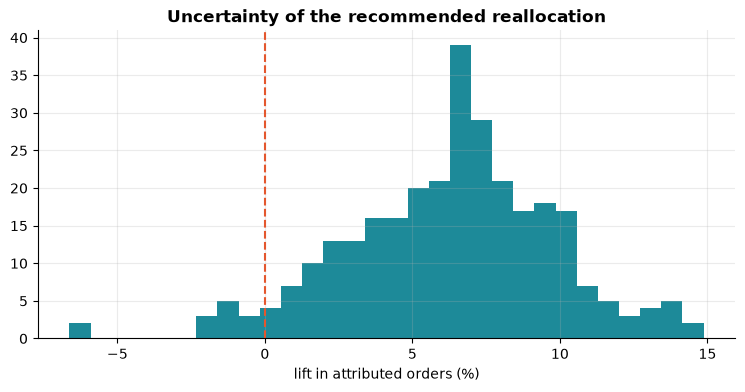

In [7]:
# Is the improvement real or an artefact of noisy elasticities?  Evaluate the SAME recommended split under each bootstrap draw.
lifts = []
for b in range(B):
    bb = {c: beta_bs[c][b] for c in chs}; cc = {c: c0_bs[c][b] for c in chs}
    pb = {**params, "beta": bb, "c0": cc}
    lifts.append(MK.total_orders(pb, opt["alloc"]) / MK.total_orders(pb, S_c) - 1)
lifts = np.array(lifts)
print(f"lift of recommended split across {B} bootstrap fits: median {np.median(lifts):+.1%}, 90% interval [{np.percentile(lifts, 5):+.1%}, {np.percentile(lifts, 95):+.1%}], P(lift > 0) = {(lifts > 0).mean():.0%}  [covers sampling noise only - NOT attribution bias or extrapolation to the 50%/150% bounds]")
plt.hist(lifts * 100, bins=30, color=TEAL); plt.axvline(0, color=RED, ls="--"); plt.xlabel("lift in attributed orders (%)"); plt.title("Uncertainty of the recommended reallocation"); plt.show()

In [8]:
cfg.save_model("marketing_response", {**params, "beta_ci": {c: (beta_tab.loc[c, "ci_low"], beta_tab.loc[c, "ci_high"]) for c in chs},
                                      "beta_boot": {c: np.array(beta_bs[c][:100]) for c in chs}, "c0_boot": {c: np.array(c0_bs[c][:100]) for c in chs}, "data_source": SOURCE})
cfg.save_serving("marketing_channel_summary", ch_sum.reset_index().round(3))
cfg.save_metrics("07_marketing", {"holdout_r2": val["holdout R2 vs mean"].round(3).to_dict(), "beta": beta_tab.round(3).to_dict("index"),
                                  "optimiser_lift": float(opt["orders"] / opt["orders_current"] - 1), "lift_p5": float(np.percentile(lifts, 5)), "lift_p95": float(np.percentile(lifts, 95)),
                                  "p_lift_positive": float((lifts > 0).mean()), "alloc_change_pct": mix["change %"].round(1).to_dict(),
                                  "caveat": "attributed orders are platform-reported and far exceed ledger orders; only relative efficiency is trusted"}, DATA_DIR)

WindowsPath('D:/HVIA Internship/task 2/cottonil-ai/artifacts/metrics/07_marketing.json')

## Takeaways
* Read **β with its confidence interval**: only channels whose whole interval is below 1 have *demonstrated* diminishing returns.
* Treat the optimiser's lift as a **hypothesis to test** (geo-split or holdout test), not a promise – attribution data is not causal.
* The app lets you drag channel budgets and see the predicted effect together with the uncertainty band.